# Problem Set 3: Portfolio Choice under Wealth Taxes and Capital Income Taxes

## Part IV: Computational Exercise

An infinitely lived investor with Epstein–Zin preferences (β = 0.96, IES θ = 1.5, risk aversion γ = 5) splits savings between a safe asset (r_s = 2%) and a risky asset that returns −10% or +20% with equal probability. The notebook solves the no-tax portfolio and consumption choice, compares a 2% wealth tax with a capital income tax that raises the same expected revenue, simulates 10,000 wealth paths over 100 periods under each regime, and compares the exact portfolio share with the Merton approximation.

In [1]:
using Roots, Plots, Statistics, Printf, Random
Random.seed!(109)   # reproducible Monte Carlo draws in Question 14

# ── Parameters ───────────────────────────────────────────────────────────────
β      = 0.96
θ      = 1.5
γ      = 5.0
r_s    = 0.02
r_r    = [-0.10, 0.20]
π_prob = [0.5, 0.5]

R_s = 1 + r_s        # 1.02
R_r = 1 .+ r_r       # [0.90, 1.20]

# Portfolio gross return in state s (pre-tax)
Rp(s, wr) = R_r[s] * wr + R_s * (1 - wr)

Rp (generic function with 1 method)

Here I am just getting the parameters and the portfolio gross returns formula down because those are universal values.

## Question 12: No-Tax Baseline

In [2]:
# Portfolio FOC (eq 1.12)
foc(wr) = sum(π_prob[s] * Rp(s, wr)^(-γ) * (R_r[s] - R_s) for s in 1:2)

# Solve for wʳ* by bisection on [0.0, 3.0]
wr_star = find_zero(foc, (0.0, 3.0), Bisection())

# Certainty equivalent ℛ* (CRRA CE of Rp)
R_star = sum(π_prob[s] * Rp(s, wr_star)^(1 - γ) for s in 1:2)^(1 / (1 - γ))

# MPC x* (Proposition 1.1 / eq 1.15)
x_star = 1 - β^θ * R_star^(θ - 1)

println("Q12 No-Tax Baseline:")
println("  wʳ*  = ", round(wr_star, digits=6))
println("  ℛ*   = ", round(R_star,  digits=6))
println("  x*   = ", round(x_star,  digits=6))

Q12 No-Tax Baseline:


  wʳ*  = 0.277817
  ℛ*   = 1.024132
  x*   = 0.048114


For Question 12, I simply solved the portfolio FOC for wr* through bisection. After that, I was able to calculate the R* equivalent with the two different interest rates and their probabilities for the risky asset. The agent places 27.8% of their savings in the risky asset and the rest in the safe asset. Their certainty equivalent return is 2.4%, and optimal consumption is 4.8% of wealth each period.

## Question 13: Solve Under Each Tax

### Wealth Tax

In [3]:
τ_w = 0.02   # wealth tax rate

# No-tax growth moments
mean_logRp_0 = sum(π_prob[s] * log(Rp(s, wr_star)) for s in 1:2)
Eg_0   = log(1 - x_star) + mean_logRp_0
Varg_0 = sum(π_prob[s] * (log(Rp(s, wr_star)) - mean_logRp_0)^2 for s in 1:2)

# Wealth tax: wʳ* and ℛ* unchanged; only MPC changes (eq 1.20)
wr_w  = wr_star
Rce_w = R_star
x_w   = 1 - β^θ * ((1 - τ_w) * R_star)^(θ - 1)

Tw_W = τ_w        # T_w / W = τ_w  (tax on stock)
Cg_w = Tw_W       # C^g = T / p^c = τ_w  (p^c = 1)

# Exact closed form E[g_w] = θ*log(1-τ_w) + E[g_0]  (eq 1.48)
Eg_w   = θ * log(1 - τ_w) + Eg_0
Varg_w = Varg_0   # wʳ* unchanged → same Rp distribution

println("Q13 Wealth Tax (τ_w = $τ_w):")
println("  wʳ*   = ", round(wr_w,   digits=6), "  (unchanged)")
println("  ℛ*    = ", round(Rce_w,  digits=6), "  (unchanged)")
println("  x*    = ", round(x_w,    digits=6))
println("  T/W   = ", round(Tw_W,   digits=6))
println("  C^g   = ", round(Cg_w,   digits=6))
println("  E[g]  = ", round(Eg_w,   digits=6))
println("  Var[g]= ", round(Varg_w, digits=8))

Q13 Wealth Tax (τ_w = 0.02):
  wʳ*   = 0.277817  (unchanged)
  ℛ*    = 1.024132  (unchanged)
  x*    = 0.057681
  T/W   = 0.02
  C^g   = 0.02
  E[g]  = -0.052496
  Var[g]= 0.00164402


We are now looking at optimal consumption under each tax, starting with wealth tax. The wealth tax had no effect on optimal weights in the risky or safe asset, as predicted, and the certainty equivalent return did not change either. There was an increase in optimal consumption from 4.8% to 5.8%, since the wealth tax reduces the after-tax return on saving, making the agent prefer to consume more today. The expected growth rate is about -5.2% per period, compared to -2.2% with no tax. Part of this is the tax itself, which takes 2% of wealth every period, and part is that even without taxes growth is negative because β and R* lead the agent to prefer spending today over saving for the next period. Variance of growth rate is very low.

### Capital Income Tax

In [4]:
# After-tax portfolio gross return
R̃p(s, wr, τr) = 1 + (1 - τr) * (r_s + wr * (r_r[s] - r_s))

# Portfolio FOC under income tax
foc_r(wr, τr) = sum(π_prob[s] * R̃p(s, wr, τr)^(-γ) * (R_r[s] - R_s) for s in 1:2)

function wr_r(τr)
    # Upper bound: max wr s.t. R̃p > 0 in bad state (s=1, r_r = -0.10)
    # 1 + (1-τr)*(r_s + wr*(r_r[1]-r_s)) > 0  ⟹  wr < (1+(1-τr)*r_s)/((1-τr)*(r_s-r_r[1]))
    wr_max = (1 + (1 - τr) * r_s) / ((1 - τr) * (r_s - r_r[1])) * 0.9999
    find_zero(wr -> foc_r(wr, τr), (0.0, wr_max), Bisection())
end

# Certainty equivalent of R̃p, MPC
R_star_r(τr) = sum(π_prob[s] * R̃p(s, wr_r(τr), τr)^(1 - γ) for s in 1:2)^(1 / (1 - γ))
x_r(τr)      = 1 - β^θ * R_star_r(τr)^(θ - 1)

# Expected pre-tax capital income per W
E_rp_pretax(τr) = sum(π_prob[s] * (R_r[s] * wr_r(τr) + R_s * (1 - wr_r(τr)) - 1) for s in 1:2)

# Revenue: τr * (1-x) * E[rᵖ_pretax]
ETr_W(τr) = τr * (1 - x_r(τr)) * E_rp_pretax(τr)

# Initial guess: τr_guess = τ_w / ((1-x_star) * E[rᵖ at no-tax])
E_rp_0   = sum(π_prob[s] * (Rp(s, wr_star) - 1) for s in 1:2)
τr_guess = τ_w / ((1 - x_star) * E_rp_0)

# Equalization: find τr s.t. C^g_r = C^g_w
h(τr) = ETr_W(τr) - Cg_w
τr_star = find_zero(h, (0.0, 0.99), Bisection())

# Compute equilibrium at τr_star
wr_r_star  = wr_r(τr_star)
Rce_r_star = R_star_r(τr_star)
x_r_star   = x_r(τr_star)
Cg_r       = ETr_W(τr_star)

mean_logR̃p_r = sum(π_prob[s] * log(R̃p(s, wr_r_star, τr_star)) for s in 1:2)
Eg_r   = log(1 - x_r_star) + mean_logR̃p_r
Varg_r = sum(π_prob[s] * (log(R̃p(s, wr_r_star, τr_star)) - mean_logR̃p_r)^2 for s in 1:2)

println("Q13 Capital-Income Tax (τr* s.t. C^g_r = C^g_w):")
println("  τr*   = ", round(τr_star,    digits=6))
println("  wʳ*   = ", round(wr_r_star,  digits=6))
println("  ℛ*    = ", round(Rce_r_star, digits=6))
println("  x*    = ", round(x_r_star,   digits=6))
println("  T/W   = ", round(Cg_r,       digits=6))
println("  C^g   = ", round(Cg_r,       digits=6))
println("  E[g]  = ", round(Eg_r,       digits=6))
println("  Var[g]= ", round(Varg_r,     digits=8))
println("  Initial τr guess = ", round(τr_guess, digits=6))
println("  Check C^g_r = C^g_w: diff = ", abs(Cg_r - Cg_w))

Q13 Capital-Income Tax (τr* s.t. C^g_r = C^g_w):


  τr*   = 0.550801
  wʳ*   = 0.611793
  ℛ*    = 1.013071
  x*    = 0.053269
  T/W   = 0.02
  C^g   = 0.02
  E[g]  = -0.03848
  Var[g]= 0.00164402
  Initial τr guess = 0.741531
  Check C^g_r = C^g_w: diff = 0.0


The first thing I did was set up an equation to find the optimal weights under the capital income tax case. This was also done using bisection. Then I used the certainty equivalent formula and the closed-form solution for the optimal consumption share to find x*. Unlike the wealth tax, here both the portfolio weight and the certainty equivalent change, which makes this case tougher to model. Next, I had to find the optimal capital income tax rate. To do this I computed an initial guess from the closed-form approximation that we used earlier in the problem set (printed for comparison), and then used bisection to find the true tax rate that made government consumption equal in both cases. After finding the tax rate, I used the earlier formulas and numerical methods to find optimal share of risky asset, the certainty equivalent, optimal shares of consumption, and expected growth rate.

Expected growth was higher than in the wealth tax case (-3.8% vs. -5.2%), and the capital income tax rate was 55%, well below the initial guess of 74%. The risky share more than doubled to 61%. The variance stayed exactly the same in this problem, because with two equally likely states the portfolio FOC pins down the ratio of the after-tax returns across the two states. Share of consumption decreased very slightly compared to the wealth tax scenario.

## Question 14: Simulation and Plots

In [5]:
N = 10_000   # paths
T = 100      # periods

# Per-period log growth factor for each scenario and state
log_g_notax  = [log((1 - x_star)   * Rp(s, wr_star))              for s in 1:2]
log_g_wealth = [log((1 - τ_w) * (1 - x_w) * Rp(s, wr_star))      for s in 1:2]
log_g_income = [log((1 - x_r_star) * R̃p(s, wr_r_star, τr_star))  for s in 1:2]

# Draw N×T i.i.d. states (shared across scenarios for comparability)
rng_states = rand(1:2, N, T)

function simulate_log_wealth(log_g_vec)
    logW = zeros(N, T + 1)   # log(W_0) = 0
    for t in 1:T, n in 1:N
        logW[n, t+1] = logW[n, t] + log_g_vec[rng_states[n, t]]
    end
    return logW
end

logW_notax  = simulate_log_wealth(log_g_notax)
logW_wealth = simulate_log_wealth(log_g_wealth)
logW_income = simulate_log_wealth(log_g_income)
println("Simulation complete.")

Simulation complete.


### Figure 1: Distribution of log W at t = 100

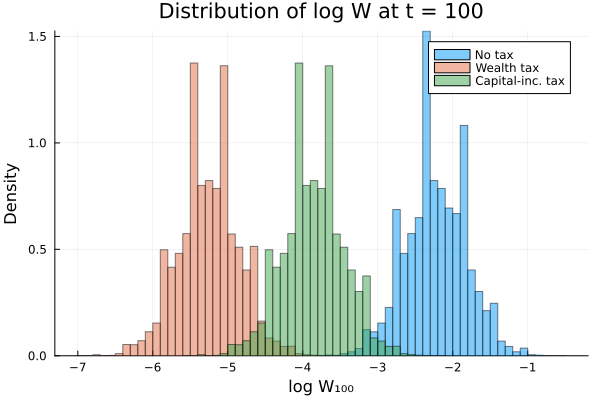

In [6]:
fig1 = plot(title = "Distribution of log W at t = 100", xlabel = "log W₁₀₀", ylabel = "Density")
histogram!(fig1, logW_notax[:,  end], label = "No tax",           normed = true, alpha = 0.5, bins = 60)
histogram!(fig1, logW_wealth[:, end], label = "Wealth tax",       normed = true, alpha = 0.5, bins = 60)
histogram!(fig1, logW_income[:, end], label = "Capital-inc. tax", normed = true, alpha = 0.5, bins = 60)
savefig(fig1, "figures/q14_fig1_logW_dist.png")
fig1

### Figure 2: Realized Average Growth Rate

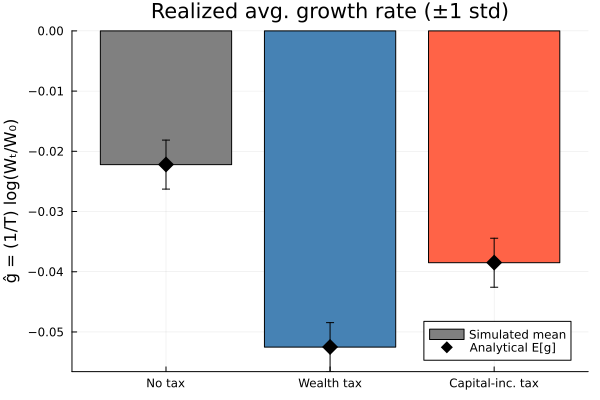

In [7]:
g_notax  = logW_notax[:,  end] ./ T
g_wealth = logW_wealth[:, end] ./ T
g_income = logW_income[:, end] ./ T

labels   = ["No tax", "Wealth tax", "Capital-inc. tax"]
means    = [mean(g_notax), mean(g_wealth), mean(g_income)]
stds     = [std(g_notax),  std(g_wealth),  std(g_income)]
analytic = [Eg_0,          Eg_w,           Eg_r]

fig2 = bar(labels, means, yerror = stds, legend = :bottomright, label = "Simulated mean",
           title = "Realized avg. growth rate (±1 std)",
           ylabel = "ĝ = (1/T) log(Wₜ/W₀)", color = [:gray, :steelblue, :tomato])
scatter!(fig2, labels, analytic, marker = :diamond, ms = 8,
         color = :black, label = "Analytical E[g]")
savefig(fig2, "figures/q14_fig2_growth.png")
fig2

In [8]:
println("Q14 Simulation Results:")
println("  Scenario              Sim E[g]    Analytical E[g]   Sim Std[g]")
for (lab, mg, ag, sg) in zip(labels, means, analytic, stds)
    @printf("  %-22s %8.5f    %8.5f          %8.5f\n", lab, mg, ag, sg)
end

Q14 Simulation Results:
  Scenario              Sim E[g]    Analytical E[g]   Sim Std[g]
  No tax                 -0.02221    -0.02219           0.00407
  Wealth tax             -0.05252    -0.05250           0.00407


  Capital-inc. tax       -0.03850    -0.03848           0.00407


### Merton Approximation

In [9]:
# Merton approximation: wʳ ≈ (E[rʳ] − r_s) / (γ σ²)
Er_r      = sum(π_prob .* r_r)
σ2_r      = sum(π_prob .* (r_r .- Er_r) .^ 2)
wr_merton = (Er_r - r_s) / (γ * σ2_r)

println("Merton approximation wʳ ≈ ", round(wr_merton, digits=4))
println("Exact (numerical) wʳ*   = ", round(wr_star,   digits=4))
println("Relative error          = ", round(100 * (wr_merton - wr_star) / wr_star, digits=2), "%")

Merton approximation wʳ ≈ 0.2667


Exact (numerical) wʳ*   = 0.2778
Relative error          = -4.01%


The Merton approximation is pretty accurate with the baseline parameters. The Merton approximation returns 0.2667 which is around 4% off what we got through our computational methods (0.2778). Since the Merton approximation is a second order approximation it is not perfectly accurate. Mainly, it breaks down when sigma(r) is large, since the approximation only uses the mean and variance of the risky return. When sigma(r) is large, that causes issues in the higher order terms of the Taylor expansion that are not accounted for in the Merton approximation.

## Question 15

Going back to Problem 7, I would change it to prefer the capital income case. The results show that there is a higher growth rate under the capital income tax even though the tax rate is so high. This means that it does effectively push consumers to partake in more risky assets which is better for the overall growth rate. That being said, I think it is important to be wary about the simplified model. We still assume, like we did earlier, that all of the agents face the same return distribution and that some are not better than others at investing. If that were not the case, I would like to redo the simulation to see that aspect. But for now, assuming that all investors are equal, the capital income tax is preferred over the wealth tax.